In [20]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdmolops
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
from copy import deepcopy
import pandas as pd

def draw_highlighted_atoms(mol, atom_ids):
    
    local_mol = deepcopy(mol)  # Create a deep copy of the molecule to avoid modifying the original
    for i, atom in enumerate(local_mol.GetAtoms()):
        # For each atom, set the property "molAtomMapNumber" to a custom number, let's say, the index of the atom in the molecule
        atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))
    
    # Create a list of atom indices to highlight
    highlight_atoms = set(atom_ids)

    # Generate image with highlighted atoms
    img = Draw.MolToImage(local_mol, highlightAtoms=highlight_atoms, size=(300, 300))

    return img

In [35]:
#smarts_train_fp = "../../data/smarts/fraggnn_d3_ma_mi/smarts_train.csv"
#smarts_train_df = pd.read_csv(smarts_train_fp)

#smarts_val_fp = "../../data/smarts/fraggnn_d3_ma_mi/smarts_val.csv"
#smarts_val_df = pd.read_csv(smarts_val_fp)

#smarts_test_fp = "../../data/smarts/fraggnn_d3_ma_mi/smarts_test.csv"
#smarts_test_df = pd.read_csv(smarts_test_fp)


smarts_train_fp = "../../data/smarts/debug_tiny/smarts_train.csv"
smarts_train_df = pd.read_csv(smarts_train_fp)

smarts_val_fp = "../../data/smarts/debug_tiny/smarts_val.csv"
smarts_val_df = pd.read_csv(smarts_val_fp)

smarts_test_fp = "../../data/smarts/debug_tiny/smarts_test.csv"
smarts_test_df = pd.read_csv(smarts_test_fp)

In [22]:
import pandas as pd

def get_smarts_df_stats(smarts_dict):
    """
    Generate statistics from a dictionary of {name: DataFrame}, 
    where each DataFrame contains 'prec_type', 'formula', and 'smiles' columns.

    Returns a summary DataFrame with:
    - Total and unique counts of formulas and SMILES per prec_type per dataset
    - Count of overlapping unique formulas and SMILES across prec_types in each dataset
    """
    summary_rows = []

    for name, df in smarts_dict.items():
        grouped = df.groupby('prec_type')
        formula_counts = grouped['formula'].count()
        smiles_counts = grouped['smiles'].count()
        unique_formulas = grouped['formula'].nunique()
        unique_smiles = grouped['smiles'].nunique()

        for prec_type in grouped.groups.keys():
            summary_rows.append({
                'dataset': name,
                'prec_type': prec_type,
                'formula_count': formula_counts[prec_type],
                'smiles_count': smiles_counts[prec_type],
                'unique_formulas': unique_formulas[prec_type],
                'unique_smiles': unique_smiles[prec_type]
            })

        # Overlap calculations using unique formulas/SMILES only
        formula_sets = grouped['formula'].apply(lambda x: set(x.unique()))
        smiles_sets = grouped['smiles'].apply(lambda x: set(x.unique()))

        overlapping_formulas = set.intersection(*formula_sets) if len(formula_sets) > 1 else set()
        overlapping_smiles = set.intersection(*smiles_sets) if len(smiles_sets) > 1 else set()

        summary_rows.append({
            'dataset': name,
            'prec_type': 'OVERLAP',
            'formula_count': len(overlapping_formulas),
            'smiles_count': len(overlapping_smiles),
            'unique_formulas': len(overlapping_formulas),
            'unique_smiles': len(overlapping_smiles)
        })

    return pd.DataFrame(summary_rows)


smarts_dict = {
    'train': smarts_train_df,
    'val': smarts_val_df,
    'test': smarts_test_df
}
get_smarts_df_stats(smarts_dict)

,dataset,prec_type,formula_count,smiles_count,unique_formulas,unique_smiles
0,train,[M+H]+,2497011,2497011,106500,972472
1,train,OVERLAP,0,0,0,0
2,val,[M+H]+,824715,824715,55413,362962
3,val,OVERLAP,0,0,0,0
4,test,[M+H]+,880071,880071,58303,389129
5,test,OVERLAP,0,0,0,0


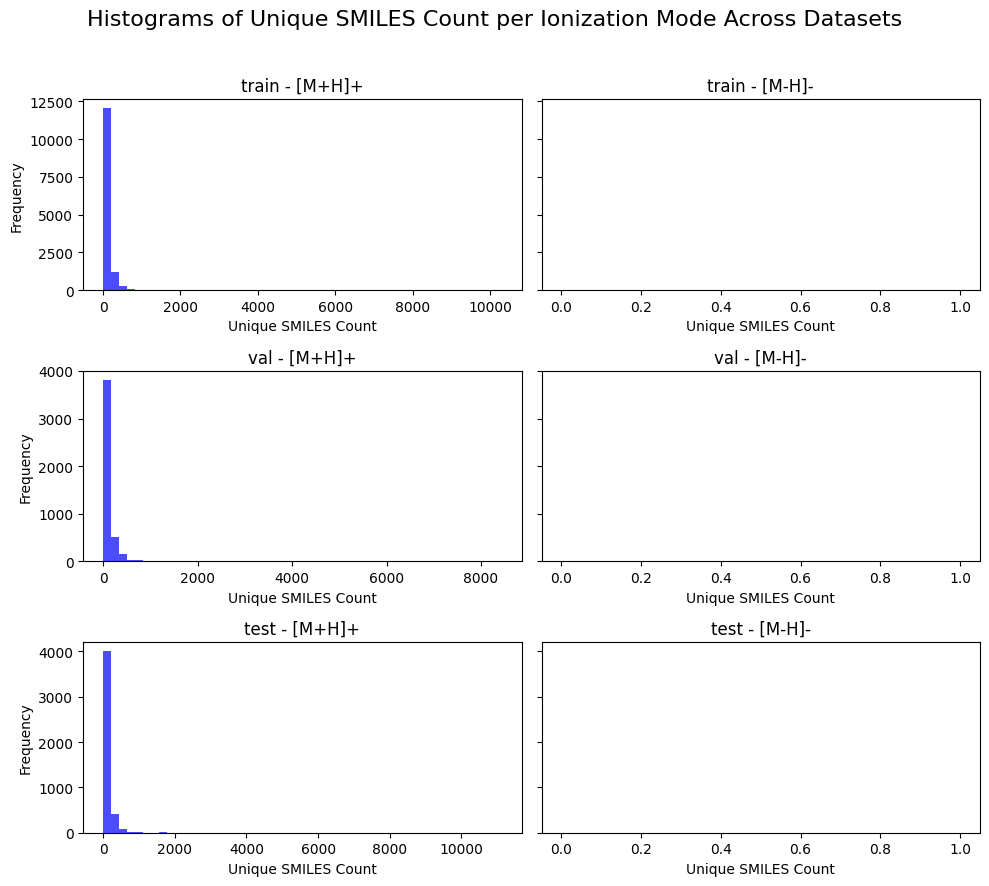

In [36]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_unique_smiles_histograms(smarts_dict, smiles_col='smiles', mol_col='mol_smiles', prec_col='prec_type', bins=50):
    """
    Plots histograms of unique SMILES count per mol_smiles for each ionization mode ([M+H]+ and [M-H]-),
    across multiple datasets provided as a dictionary.

    Parameters:
        smarts_dict (dict): Dictionary of {name: DataFrame}, each containing precursor type, SMILES, and molecule columns.
        smiles_col (str): Column name for SMILES.
        mol_col (str): Column name for molecule identifier (e.g., canonical SMILES).
        prec_col (str): Column name for precursor type (e.g., [M+H]+ or [M-H]-).
        bins (int): Number of histogram bins.
    """
    n = len(smarts_dict)
    fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(10, 3 * n), sharey='row')

    if n == 1:
        axes = [axes]  # ensure iterable even when 1 dataset

    for idx, (name, df) in enumerate(smarts_dict.items()):
        # Count unique SMILES per mol_smiles within each prec_type
        unique_counts = (
            df.groupby([prec_col, mol_col])[smiles_col]
            .nunique()
            .reset_index()
            .rename(columns={smiles_col: 'unique_smiles_count'})
        )

        mh_plus_data = unique_counts[unique_counts[prec_col] == '[M+H]+']
        mh_minus_data = unique_counts[unique_counts[prec_col] == '[M-H]-']

        ax1, ax2 = axes[idx]

        # [M+H]+ Histogram
        ax1.hist(mh_plus_data['unique_smiles_count'], bins=bins, color='blue', alpha=0.7)
        ax1.set_title(f'{name} - [M+H]+')
        ax1.set_xlabel('Unique SMILES Count')
        ax1.set_ylabel('Frequency')

        # [M-H]- Histogram
        ax2.hist(mh_minus_data['unique_smiles_count'], bins=bins, color='orange', alpha=0.7)
        ax2.set_title(f'{name} - [M-H]-')
        ax2.set_xlabel('Unique SMILES Count')

    plt.suptitle('Histograms of Unique SMILES Count per Ionization Mode Across Datasets', fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_unique_smiles_histograms(smarts_dict)

In [37]:
import pandas as pd
from itertools import combinations

def get_unique_smiles_overlap_by_precursor(smarts_dict, smiles_col='smiles', prec_col='prec_type'):
    """
    Computes pairwise SMILES overlaps across datasets, grouped by precursor type (e.g., [M+H]+, [M-H]-).

    Parameters:
        smarts_dict (dict): Dictionary of {name: DataFrame}, each containing a SMILES and prec_type column.
        smiles_col (str): Column name for SMILES (default: 'smiles').
        prec_col (str): Column name for precursor type (default: 'prec_type').

    Returns:
        overlap_df (pd.DataFrame): DataFrame with per-precursor-type pairwise SMILES overlap stats:
            - dataset_1, dataset_2
            - overlap_count
            - overlap_%_of_dataset_1
            - overlap_%_of_dataset_2
            - prec_type
        global_overlap_dict (dict): {prec_type: set of SMILES shared across all datasets for that type}
    """
    all_prec_types = set().union(*[set(df[prec_col].dropna().unique()) for df in smarts_dict.values()])
    overlap_rows = []
    global_overlap_dict = {}

    for prec in all_prec_types:
        # Extract SMILES sets for this precursor from each dataset
        smiles_sets = {
            name: set(df[df[prec_col] == prec][smiles_col].unique())
            for name, df in smarts_dict.items()
        }

        # Remove empty sets (datasets without this precursor)
        smiles_sets = {k: v for k, v in smiles_sets.items() if v}

        # Skip if fewer than 2 datasets contain this precursor
        if len(smiles_sets) < 2:
            continue

        # Pairwise comparisons
        for (name1, set1), (name2, set2) in combinations(smiles_sets.items(), 2):
            intersect = set1 & set2
            overlap_count = len(intersect)
            percent_in_1 = 100 * overlap_count / len(set1) if set1 else 0
            percent_in_2 = 100 * overlap_count / len(set2) if set2 else 0

            overlap_rows.append({
                'prec_type': prec,
                'dataset_1': name1,
                'dataset_2': name2,
                'overlap_count': overlap_count,
                'overlap_%_of_dataset_1': round(percent_in_1, 2),
                'overlap_%_of_dataset_2': round(percent_in_2, 2),
            })

        # Global intersection for this precursor
        global_overlap_dict[prec] = set.intersection(*smiles_sets.values())

    overlap_df = pd.DataFrame(overlap_rows)
    return overlap_df, global_overlap_dict

overlap_df, global_smiles = get_unique_smiles_overlap_by_precursor(smarts_dict)
overlap_df


,prec_type,dataset_1,dataset_2,overlap_count,overlap_%_of_dataset_1,overlap_%_of_dataset_2
0,[M+H]+,train,val,89967,9.25,24.79
1,[M+H]+,train,test,90198,9.28,23.18
2,[M+H]+,val,test,53037,14.61,13.63


In [38]:
# Concatenate SMILES from all datasets
all_smiles = pd.concat([df['smiles'] for df in smarts_dict.values()])

# Compute frequency of each unique SMILES
smiles_frequency = all_smiles.value_counts()

# Display the result
smiles_frequency

smiles
*c(c*)cc*                                                                                                                                 20432
*c(cc*)cc*                                                                                                                                10614
*c(*)ccc*                                                                                                                                  9958
*c(*)cccc*                                                                                                                                 9763
*cccc*                                                                                                                                     9266
                                                                                                                                          ...  
*CC=C(*)C(O)C(*)C                                                                                                                

In [26]:
all_smarts = pd.concat([df[['smarts']] for df in smarts_dict.values()])
smart_frequency = all_smarts.value_counts()
smart_frequency

smarts                                                                                                                                                                                                                                                                                                     
[#6:1](:[#6:2]:[#6:3]:[#6:4]:[!#1]):[!#1]                                                                                                                                                                                                                                                                      8953
[#6:1](-[#6:2]-[#6:3]-[#6:4]-[!#1])-[!#1]                                                                                                                                                                                                                                                                      8209
[#6:1](:[#6:2]:[#6:3]:[!#1])(:[#6:4]:[!#1])-[!#1]                                   

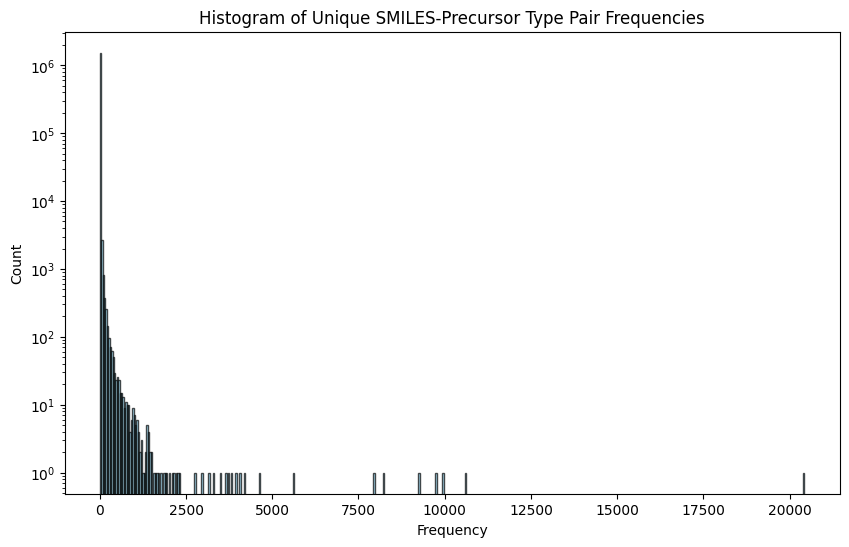

In [27]:
# Concatenate SMILES and precursor type columns from all datasets
smiles_prec_type = pd.concat([df[['smiles', 'prec_type']] for df in smarts_dict.values()])

# Compute frequency of each unique SMILES-precursor type pair
smiles_prec_type_frequency = smiles_prec_type.value_counts().reset_index(name='count')

# Plot a histogram of the frequencies
plt.figure(figsize=(10, 6))
plt.hist(smiles_prec_type_frequency['count'], bins=500, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Unique SMILES-Precursor Type Pair Frequencies')
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.yscale('log')  # Use log scale for better visualization
plt.show()

In [28]:
# Merge smiles_prec_type_frequency into smarts_train_df
smarts_train_df = smarts_train_df.merge(smiles_prec_type_frequency, on=['smiles', 'prec_type'], how='left')

# Display the updated DataFrame
smarts_train_df.head()

,node_id,smarts,smiles,mw,formula,prec_type,mol_smiles,mol_inchikey,matches,count
0,2,[#6:1]1(:[#7H:2]:[#6:3](=[#16:4]):[#7H:5]:[#6:...,*=c1[nH]c(=S)[nH]c2c1CCCC2,166.056469,C8H10*N2S,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(-2, 165.048095703125, [[165.048095703125, 19...",2
1,3,[#8:1]=[#6:2]1:[#7H:3]:[#6:4](:[#7H:5]:[#6:6]2...,*=c1[nH]c2c(c(=O)[nH]1)CCCC2,150.079313,C8H10*N2O,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(-2, 149.07093811035156, [[149.07080078125, 3...",2
2,6,[#8:1]=[#6:2](:[#6:7]1:[#6:6](:[#7H:5]:[#6:3](...,*c(=S)[nH]c1c(c(*)=O)CCCC1,167.040485,C8H9*2NOS,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(-2, 166.0321044921875, [[166.03179931640625,...",2
3,8,[#8:1]=[#6:2](:[#6:5]1:[#6:4](:[#7:3]:[!#1])-[...,*nc1c(c(*)=O)CCCC1,122.060589,C7H8*2NO,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(1, 124.07569885253906, [[124.07540130615234,...",6
4,16,[#8:1]=[#6:2](:[#7:3]:[!#1]):[#6:5]1:[#6:4](-[...,*nc(=O)c1c(*)CCCC1,122.060589,C7H8*2NO,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(1, 124.07569885253906, [[124.07540130615234,...",5


In [29]:
# Count the number of '*' in each SMILES and add it as a new column 'break'
smarts_train_df['break'] = smarts_train_df['smiles'].apply(lambda x: x.count('*'))

# Display the updated DataFrame
smarts_train_df.head()

,node_id,smarts,smiles,mw,formula,prec_type,mol_smiles,mol_inchikey,matches,count,break
0,2,[#6:1]1(:[#7H:2]:[#6:3](=[#16:4]):[#7H:5]:[#6:...,*=c1[nH]c(=S)[nH]c2c1CCCC2,166.056469,C8H10*N2S,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(-2, 165.048095703125, [[165.048095703125, 19...",2,1
1,3,[#8:1]=[#6:2]1:[#7H:3]:[#6:4](:[#7H:5]:[#6:6]2...,*=c1[nH]c2c(c(=O)[nH]1)CCCC2,150.079313,C8H10*N2O,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(-2, 149.07093811035156, [[149.07080078125, 3...",2,1
2,6,[#8:1]=[#6:2](:[#6:7]1:[#6:6](:[#7H:5]:[#6:3](...,*c(=S)[nH]c1c(c(*)=O)CCCC1,167.040485,C8H9*2NOS,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(-2, 166.0321044921875, [[166.03179931640625,...",2,2
3,8,[#8:1]=[#6:2](:[#6:5]1:[#6:4](:[#7:3]:[!#1])-[...,*nc1c(c(*)=O)CCCC1,122.060589,C7H8*2NO,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(1, 124.07569885253906, [[124.07540130615234,...",6,2
4,16,[#8:1]=[#6:2](:[#7:3]:[!#1]):[#6:5]1:[#6:4](-[...,*nc(=O)c1c(*)CCCC1,122.060589,C7H8*2NO,[M+H]+,O=c1[nH]c(=S)[nH]c2c1CCCC2,BRCPOVNFTXLBPI-UHFFFAOYSA-N,"[(1, 124.07569885253906, [[124.07540130615234,...",5,2


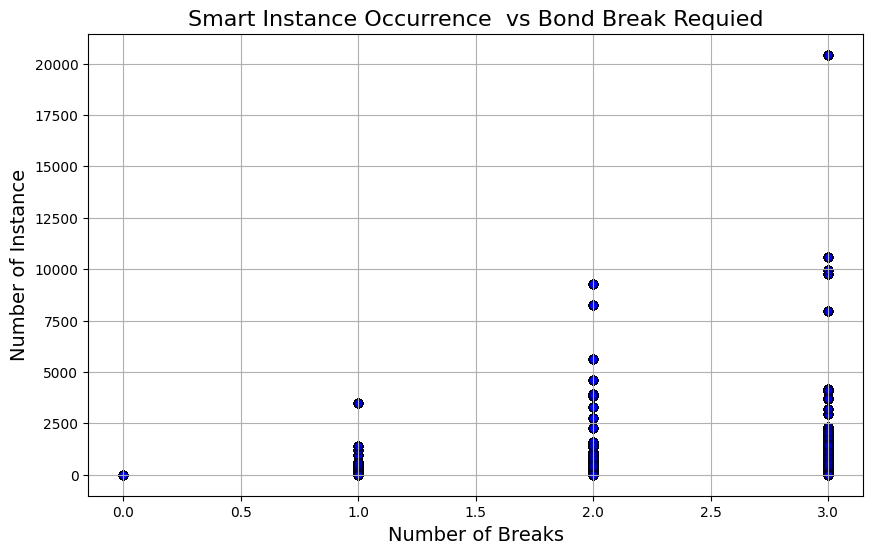

In [30]:
plt.figure(figsize=(10, 6))

# Scatter plot for count vs break
plt.scatter(smarts_train_df['break'], smarts_train_df['count'], alpha=0.1, color='blue', edgecolor='black')

# Add labels and title
plt.title('Smart Instance Occurrence  vs Bond Break Requied', fontsize=16)
plt.xlabel('Number of Breaks', fontsize=14)
plt.ylabel('Number of Instance', fontsize=14)

# Show the plot
plt.grid(True)
plt.show()

In [31]:
inchikey_prec_example_df = smarts_train_df[(smarts_train_df['mol_inchikey'] == 'AAAQFGUYHFJNHI-UHFFFAOYSA-N') \
                                           & (smarts_train_df['prec_type'] == '[M+H]+')]
inchikey_prec_example_df

,node_id,smarts,smiles,mw,formula,prec_type,mol_smiles,mol_inchikey,matches,count,break
68537,6,[#6:1](=[#8:2])(-[#6:3]-[#6:4]1-[#7:5]=[#6:6](...,*C(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C)n...,379.096178,C20H16*ClN4O2,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(-1, 379.09564208984375, [[379.095703125, 999...",2,1
68538,7,[#6:1]-[#6:2]-[#7:3]-[#6:4](-[#6:5]-[#6:6]1-[#...,*=C(CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C)nnc...,407.151288,C22H22*ClN5O,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(-2, 406.14288330078125, [[406.14300537109375...",2,1
68539,10,[#6:1](-[#6:2]1-[#7:3]=[#6:4](-[#6:5]2:[#6:6]:...,*CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C)nnc21,351.101264,C19H16*ClN4O,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(-1, 351.1007080078125, [[351.1017150878906, ...",2,1
68540,12,[#6:1]1(-[#7:2]=[#6:3](-[#6:4]2:[#6:5]:[#6:6]:...,*C1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C)nnc21,337.085614,C18H14*ClN4O,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(-1, 337.0850524902344, [[337.0851135253906, ...",2,1
68541,30,[#6:1](-[#7:2]-[#6:3](=[#8:4])-[#6:5]-[#6:6]1-...,*CNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(*)ccc2-n2c(C)...,377.104338,C20H16*2ClN5O,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(0, 378.1116027832031, [[378.11138916015625, ...",2,2
...,...,...,...,...,...,...,...,...,...,...,...
294664,751,[#6:1]-[#6:2]-[#7:3]-[#6:4](=[#8:5])-[#6:6]-[#...,*c1ccc(OC)cc1C(=NC(CC(=O)NCC)c(*)nnc(*)C)c1ccc...,409.143129,C22H22*3ClN4O2,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(-3, 407.1269226074219, [[407.126708984375, 2...",2,3
294665,753,[#7:1]1(:[#6:2](:[#7:3]:[#7:4]:[#6:5]:1-[!#1])...,*c1nnc(*)n1*,66.009222,C2*3N3,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(1, 68.02433013916016, [[68.02410125732422, 1...",13,3
294666,754,[#6:1]-[#6:2]-[#7:3]-[#6:4](=[#8:5])-[#6:6]-[#...,*c1ccc(OC)cc1C(=NC(CC(=O)NCC)c(*)nn*)c1ccc(Cl)cc1,382.119654,C20H19*3ClN4O2,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(-4, 379.0956115722656, [[379.09521484375, 14...",2,3
294667,757,[#7:1](:[#6:2](-[#6:3]):[#7:4]:[!#1])(-[!#1]):...,*n(*)c(C)n*,55.029623,C2H3*3N2,[M+H]+,CCNC(=O)CC1N=C(c2ccc(Cl)cc2)c2cc(OC)ccc2-n2c(C...,AAAQFGUYHFJNHI-UHFFFAOYSA-N,"[(1, 57.04472351074219, [[57.044498443603516, ...",26,3


In [32]:
# Count the frequency of each unique molecular weight (mw)
mw_frequency = inchikey_prec_example_df['mw'].value_counts()

# Display the result
mw_frequency

mw
338.093439    14
379.119988    14
324.077789     9
382.107077     9
381.099252     9
              ..
147.068414     1
161.071488     1
67.018390      1
66.009222      1
354.113506     1
Name: count, Length: 138, dtype: int64

In [33]:
# De-duplicate by 'smiles'
deduplicated_df = inchikey_prec_example_df.reset_index().drop_duplicates(subset='smiles')

# Count the frequency of each unique molecular weight (mw)
mw_frequency_deduplicated = deduplicated_df['mw'].value_counts()

# Display the result
mw_frequency_deduplicated

mw
324.077789    7
381.099252    7
382.107077    6
379.119988    5
338.093439    5
             ..
147.068414    1
161.071488    1
67.018390     1
66.009222     1
354.113506    1
Name: count, Length: 138, dtype: int64

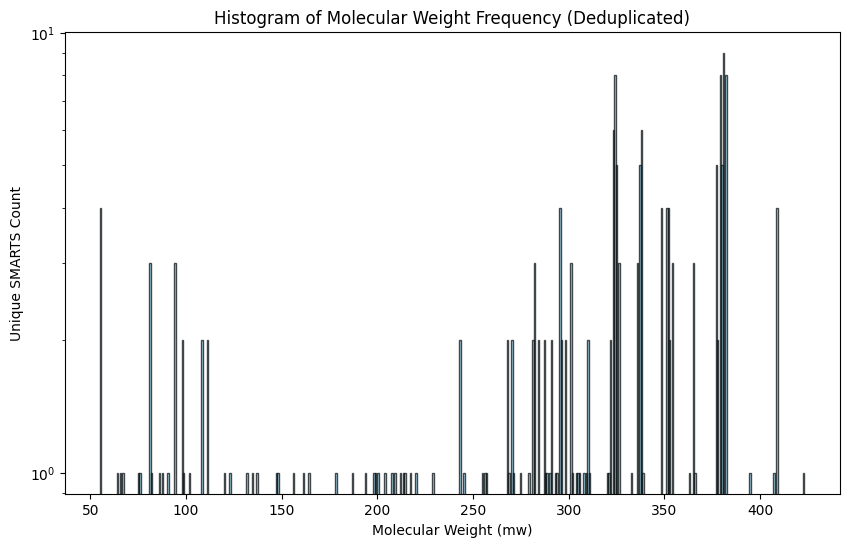

In [34]:
plt.figure(figsize=(10, 6))
plt.hist(mw_frequency_deduplicated.index, weights=mw_frequency_deduplicated.values, bins=500, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Molecular Weight Frequency (Deduplicated)')
plt.xlabel('Molecular Weight (mw)')
plt.ylabel('Unique SMARTS Count')
plt.yscale('log')  # Use log scale for better visualization
plt.show()

## NL Smarts

In [39]:
nl_smarts_train_fp = "../../data/smarts/fraggnn_d3_ma_mi/nl_smarts_train.csv"
nl_smarts_train_df = pd.read_csv(nl_smarts_train_fp)

nl_smarts_val_fp = "../../data/smarts/fraggnn_d3_ma_mi/nl_smarts_val.csv"
nl_smarts_val_df = pd.read_csv(nl_smarts_val_fp)

nl_smarts_test_fp = "../../data/smarts/fraggnn_d3_ma_mi/nl_smarts_test.csv"
nl_smarts_test_df = pd.read_csv(nl_smarts_test_fp)


In [41]:
nl_smarts_dict = {
    'train': nl_smarts_train_df,
    'val': nl_smarts_val_df,
    'test': nl_smarts_test_df
}
get_smarts_df_stats(nl_smarts_dict)

,dataset,prec_type,formula_count,smiles_count,unique_formulas,unique_smiles
0,train,[M+H]+,31696607,31696607,120686,543844
1,train,OVERLAP,0,0,0,0
2,val,[M+H]+,10886151,10886151,63003,201646
3,val,OVERLAP,0,0,0,0
4,test,[M+H]+,10970143,10970143,65507,208089
5,test,OVERLAP,0,0,0,0


In [43]:
# Concatenate SMILES from all datasets
nl_all_smiles = pd.concat([df['smiles'] for df in nl_smarts_dict.values()])

# Compute frequency of each unique SMILES
nl_smiles_frequency = nl_all_smiles.value_counts()

# Display the result
nl_smiles_frequency

smiles
*C                               6087906
*O                               5838272
*=O                              5724341
*c*                              1641458
*N                                937849
                                  ...   
*c(ccc(Cl)c(*)Cl)NC(=O)NC1CC1          1
*cc(cc(Cl)c(*)Cl)NC(=O)NC1CC1          1
*c(cc(Cl)c(*)Cl)NC(=O)NC1CC1           1
*cc(Cl)c(Cl)cc(*)NC(=O)NC1CC1          1
*c1cc(NC(=O)NC2CC2)ccc1Cl              1
Name: count, Length: 853672, dtype: int64

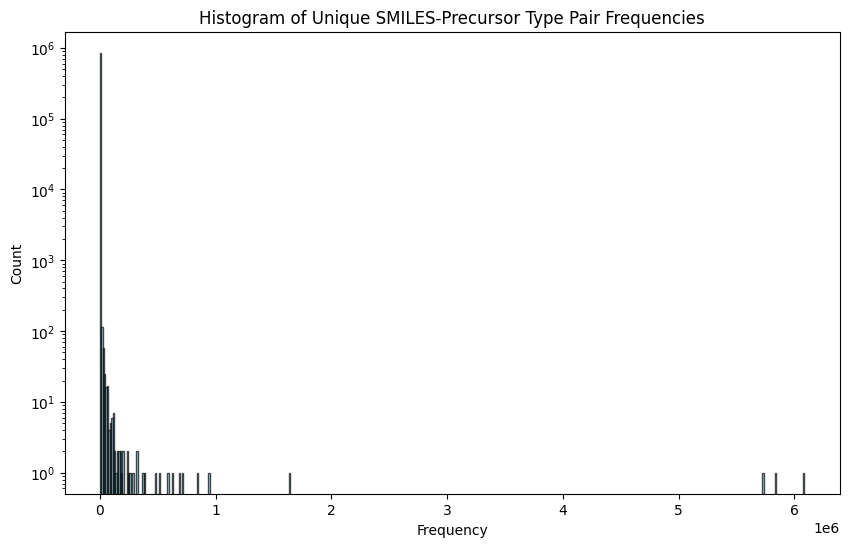

In [44]:
# Concatenate SMILES and precursor type columns from all datasets
nl_smiles_prec_type = pd.concat([df[['smiles', 'prec_type']] for df in nl_smarts_dict.values()])

# Compute frequency of each unique SMILES-precursor type pair
nl_smiles_prec_type_frequency = nl_smiles_prec_type.value_counts().reset_index(name='count')

# Plot a histogram of the frequencies
plt.figure(figsize=(10, 6))
plt.hist(nl_smiles_prec_type_frequency['count'], bins=500, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Histogram of Unique SMILES-Precursor Type Pair Frequencies')
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.yscale('log')  # Use log scale for better visualization
plt.show()